# 03b · Refusal circuits per form (CircuitKIT)

Discovers the node-level circuit (attention heads + MLPs) behind the refusal-vs-comply decision separately for English and Hinglish prompts, then asks how much of the English refusal circuit is still at work on Hinglish.

* clean = harmful prompt → refusal token, corrupt = its benign twin → compliance token (explicit contrastive pairs, as CircuitKIT recommends for instruction-style data; pairs are left-padded to align)
* algorithm `eap-ig` at node level, then patching / ablation faithfulness, and the English circuit is scored on the Hinglish task

Runs on CircuitKIT's TransformerLens port for Tiny Aya (`cohere2`). Use a fresh runtime: CircuitKIT pins `transformer-lens==3.8.0`. An L4 or A100 is strongly recommended; on a T4 keep `N_EXAMPLES` small.

In [1]:
import os, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/multilingual_safety"  # upload the folder here
else:
    PROJECT_DIR = os.path.abspath(".")

assert os.path.exists(os.path.join(PROJECT_DIR, "mlsafety.py")), f"multilingual_safety folder not found at {PROJECT_DIR}"
os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)

Mounted at /content/drive


In [2]:
%pip install -q circuitkit "auditkit[transformers]" pandas matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
from huggingface_hub import login

token = os.environ.get("HF_TOKEN")
if token is None and IN_COLAB:
    from google.colab import userdata
    try:
        token = userdata.get("HF_TOKEN")
    except Exception:
        token = None
login(token=token)  # the token needs access to the gated CohereLabs/tiny-aya-* repos

In [4]:
import collections
import pandas as pd
import torch
import matplotlib.pyplot as plt
import circuitkit as ck
from circuitkit import register_task
from circuitkit.data.normalized import ContrastiveRecord, DatasetShape, NormalizedDataset
from circuitkit.data.normalized_task import NormalizedTaskSpec
from transformers import AutoTokenizer
import mlsafety as ms

P = ms.get_paths(PROJECT_DIR)
MODEL_KEY = "tiny-aya-global"   # use the same key in 02, 03, 03b, 04, 05; branches are listed in ms.MODELS
MODEL_ID, TAG = ms.MODELS[MODEL_KEY]["id"], ms.MODELS[MODEL_KEY]["tag"]
FORMS_TO_RUN = ["en", "hinglish","hi_roman", "hi_deva"]        # add "hi_roman", "hi_deva" if time allows
N_EXAMPLES = 32
IG_STEPS = 3
SPARSITY = 0.3
DTYPE = "bfloat16" if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else "float16"

rows = [r for r in ms.load_jsonl(P.gen(TAG)) if r["paired"]]
tok = AutoTokenizer.from_pretrained(MODEL_ID)

config.json:   0%|          | 0.00/1.96k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/8.17k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 21.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/567 [00:00<?, ?B/s]

## Answer tokens taken from the model's own replies

In [5]:
def first_token(text):
    ids = tok(text.strip(), add_special_tokens=False)["input_ids"]
    return tok.decode(ids[:1]) if ids else None

refusal_first = collections.Counter(first_token(r["response"]) for r in rows
                                    if r["form"] == "en" and r["kind"] == "harmful" and r["unsafe"] < 0.5)
comply_first = collections.Counter(first_token(r["response"]) for r in rows
                                   if r["form"] == "en" and r["kind"] == "benign" and not r["refused_heur"])
print("refusal openers:", refusal_first.most_common(5))
print("compliance openers:", comply_first.most_common(5))
REFUSE_TOK = refusal_first.most_common(1)[0][0]
COMPLY_TOK = next(t for t, _ in comply_first.most_common() if t != REFUSE_TOK)
print(f"refusal token {REFUSE_TOK!r} vs compliance token {COMPLY_TOK!r}")

refusal openers: [("I'm", 44), ('The', 3), ('**', 2), ("It's", 1), ('Here', 1)]
compliance openers: [('**', 34), ('The', 8), ('To', 3), ('In', 1), ('Develop', 1)]
refusal token "I'm" vs compliance token '**'


In [6]:
def templated(prompt):
    text = ms.chat_text(tok, prompt)
    bos = tok.bos_token or ""
    return text[len(bos):] if bos and text.startswith(bos) else text  # TransformerLens prepends BOS itself

def register_form(form):
    pairs = {}
    for r in rows:
        if r["form"] == form:
            pairs.setdefault(r["family_id"], {})[r["kind"]] = r["prompt"]
    records = [
        ContrastiveRecord(record_id=str(fid), clean_prompt=templated(p["harmful"]), clean_answer=REFUSE_TOK,
                          corrupt_prompt=templated(p["benign"]), corrupt_answer=COMPLY_TOK)
        for fid, p in sorted(pairs.items()) if {"harmful", "benign"} <= p.keys()
    ]
    name = f"refusal_{form}"
    register_task(NormalizedTaskSpec(NormalizedDataset(name=name, shape=DatasetShape.QA, records=records), name=name))
    return name

tasks = {f: register_form(f) for f in FORMS_TO_RUN}
tasks

{'en': 'refusal_en',
 'hinglish': 'refusal_hinglish',
 'hi_roman': 'refusal_hi_roman',
 'hi_deva': 'refusal_hi_deva'}

In [7]:
model = ck.load_model(MODEL_ID, dtype=DTYPE)
circuits = {}
for f, task in tasks.items():
    circuits[f] = ck.discover(model, task, algorithm="eap-ig", level="node", n_examples=N_EXAMPLES,
                              batch_size=1, sparsity=SPARSITY, ig_steps=IG_STEPS,
                              output_path=str(P.out / f"circuit_{TAG}_{f}.pt"))
    print(f, len(circuits[f]), "nodes | top:", list(circuits[f].top_nodes(8)))

/usr/local/lib/python3.13/dist-packages/circuitkit/utils/device.py:49: FutureWarning: torch.cuda._set_allocator_settings is deprecated. Use torch._C._accelerator_setAllocatorSettings instead.
  torch.cuda.memory._set_allocator_settings("expandable_segments:True")


model.safetensors.index.json:   0%|          | 0.00/23.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

... (11 outputs left out)


/usr/local/lib/python3.13/dist-packages/circuitkit/api.py:1372: RuntimeWarning: Discovery algorithm 'eap-ig' may need about 54.0 GB for qkv-flag activations (batch=1, seq=8192, heads=16, d_model=2048, layers=36, dtype=torch.bfloat16), while 12.1 GB is currently free. This estimate is advisory only; CircuitKIT will continue and let the allocator determine whether the run fits. Set CIRCUITKIT_SKIP_MEM_GUARD=1 to silence this warning.
  _check_qkv_flag_memory_headroom(
 31%|███▏      | 10/32 [00:40<01:29,  4.09s/it]

20:19:25 • tokenize_batch_pair: 1 of 1 contrastive pair(s) have unequal clean/corrupt token counts (clean max=386, corrupt max=387; 101 misaligned pair(s) across 101 batch(es) so far this process). EAP aligns by end-padding (pair_padding_side='left'), which preserves per-position correspondence ONLY when the length difference is at that end. Mid-sequence length-changing corruptions will misalign and the attribution for those pairs is unreliable — prefer minimal, token-length-preserving contrastive pairs. (Warning repeats every 100th misaligned batch.)


100%|██████████| 32/32 [02:11<00:00,  4.11s/it]

20:20:55 • Converted 612 node scores from EAP-IG graph to CircuitKIT format.
20:20:55 • Saved unified CircuitScores → /content/drive/MyDrive/multilingual_safety/outputs/circuit_global_hi_deva_scores.json
20:20:55 • Saved 'scores' → /content/drive/MyDrive/multilingual_safety/outputs/circuit_global_hi_deva_scores.pt
20:20:55 • [4/4] Identifying nodes to prune
20:20:55 • 
--- Running Categorized Node Pruning (Scope: BOTH) ---
20:20:55 • Found 576 Attention Heads and 36 MLP layers to consider for pruning.
20:20:55 • Pruning 10 out of 36 MLP layers (30%).
20:20:55 • Targeting to prune 172 out of 576 total Attention Heads (30%).
20:20:55 • Actually pruned 172 Attention Heads.
20:20:55 •   - Layer 1: Pruned 2/16 heads.
20:20:55 •   - Layer 2: Pruned 4/16 heads.
20:20:55 •   - Layer 3: Pruned 2/16 heads.
20:20:55 •   - Layer 4: Pruned 2/16 heads.
20:20:55 •   - Layer 5: Pruned 1/16 heads.
20:20:55 •   - Layer 6: Pruned 4/16 heads.
20:20:55 •   - Layer 7: Pruned 8/16 heads.
20:20:55 •   - Layer

## How much of the English refusal circuit is used on Hinglish?

top-10: Jaccard(en, hinglish) = 0.67
top-10: Jaccard(en, hi_roman) = 0.54
top-10: Jaccard(en, hi_deva) = 0.33
top-25: Jaccard(en, hinglish) = 0.67
top-25: Jaccard(en, hi_roman) = 0.61
top-25: Jaccard(en, hi_deva) = 0.61
top-50: Jaccard(en, hinglish) = 0.61
top-50: Jaccard(en, hi_roman) = 0.59
top-50: Jaccard(en, hi_deva) = 0.67


,en,hinglish
MLP 35,4.500000,2.046875
MLP 19,2.359375,1.070312
MLP 23,1.906250,0.832031
MLP 16,1.429688,0.714844
MLP 15,1.648438,0.937500
MLP 10,1.023438,0.369141
MLP 24,1.750000,1.101562
A14.13,1.835938,1.257812
MLP 25,1.125000,0.578125
A20.4,1.492188,0.964844


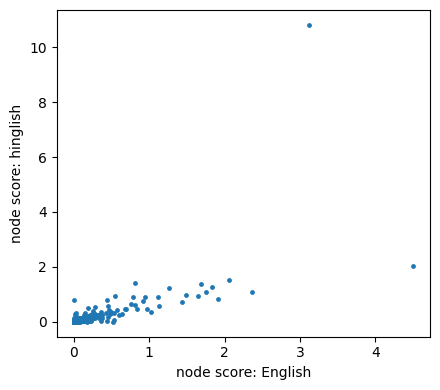

In [8]:
def top_set(c, k):
    return set(c.top_nodes(k))

for k in (10, 25, 50):
    for f in FORMS_TO_RUN[1:]:
        a, b = top_set(circuits["en"], k), top_set(circuits[f], k)
        print(f"top-{k}: Jaccard(en, {f}) = {len(a & b) / len(a | b):.2f}")

en_scores, other = circuits["en"].scores, circuits[FORMS_TO_RUN[1]].scores
common = sorted(set(en_scores) & set(other))
plt.figure(figsize=(4.5, 4))
plt.scatter([en_scores[n] for n in common], [other[n] for n in common], s=6)
plt.xlabel("node score: English"); plt.ylabel(f"node score: {FORMS_TO_RUN[1]}")
plt.tight_layout(); plt.savefig(P.out / f"fig_circuit_scores_{TAG}.png", dpi=200)

dropped = sorted(common, key=lambda n: en_scores[n] - other[n], reverse=True)[:15]
pd.DataFrame({"en": {n: en_scores[n] for n in dropped}, FORMS_TO_RUN[1]: {n: other[n] for n in dropped}})

## Faithfulness: does the English circuit explain behavior on each form?

In [9]:
rows_out = []
for circ_form in FORMS_TO_RUN:
    for task_form in FORMS_TO_RUN:
        rep = ck.faithfulness(model, circuits[circ_form], tasks[task_form], pillars=["patching", "ablation"],
                              n_examples=min(N_EXAMPLES, 32), batch_size=1)
        rows_out.append({"circuit from": circ_form, "evaluated on": task_form,
                         "patching": rep.patching_score, "ablation": rep.ablation_score})
pd.DataFrame(rows_out)

/tmp/ipykernel_500/3781907540.py:4: HyperparameterWarning: eval.num_examples=32 is outside the sensible range 100 to 1000. Faithfulness is a ratio of two noisy averages. The EAP-IG paper evaluates on 100 examples; CircuitKIT's benchmarks use 300 held-out examples.
  rep = ck.faithfulness(model, circuits[circ_form], tasks[task_form], pillars=["patching", "ablation"],


20:21:06 • Reusing cached EAP CSV: cache/normalized/refusal_en_c51c29e9d4bc52ac_unk_seed42_max32.csv
20:21:06 • Starting full faithfulness evaluation with pillars: ['patching', 'ablation']
20:21:06 🔧 Model: tiny-aya-global
20:21:06 • Task: refusal_en
20:21:06 • Algorithm: eap-ig
20:21:06 • Computing Pillar 1: Causal Patching...
20:21:06 • Pillar 1: Running causal patching evaluation...


 81%|████████▏ | 26/32 [00:36<00:08,  1.41s/it]

20:22:45 • tokenize_batch_pair: 1 of 1 contrastive pair(s) have unequal clean/corrupt token counts (clean max=382, corrupt max=376; 201 misaligned pair(s) across 201 batch(es) so far this process). EAP aligns by end-padding (pair_padding_side='left'), which preserves per-position correspondence ONLY when the length difference is at that end. Mid-sequence length-changing corruptions will misalign and the attribution for those pairs is unreliable — prefer minimal, token-length-preserving contrastive pairs. (Warning repeats every 100th misaligned batch.)


100%|██████████| 32/32 [00:45<00:00,  1.42s/it]

20:22:54 • Pillar 1 Score (Causal Patching faithfulness ratio): 0.8727 (raw ratio: 0.8727, raw metric: 4.7188, clean: 6.0312, corrupt: -4.2812)
20:22:54 •   Patching faithfulness ratio: 0.8727 (raw metric: 4.7188) (108.0s)


... (157 outputs left out)

100%|██████████| 32/32 [00:30<00:00,  1.05it/s]

21:01:16 • Pillar 2 Score (Ablation - zero faithfulness ratio): 1.0000 (raw ratio: 1.0310, raw metric: -3.6719, clean: -3.8750, corrupt: -10.4375)
21:01:16 • Pillar 2: raw ratio 1.0310 is above 1: the circuit scores higher than the full model, and the score is capped at 1.
21:01:16 •   Ablation faithfulness ratio: 1.0000 (raw metric: -3.6719) (30.5s)


21:01:17 • ======================================================================
21:01:17 ✓ FAITHFULNESS EVALUATION COMPLETE
21:01:17 • ======================================================================
21:01:17 • Total time: 142.5s
21:01:17 • Pillar timings:
21:01:17 •   patching       :   110.4s
21:01:17 •   ablation       :    30.5s
21:01:17 • ======================================================================


,circuit from,evaluated on,patching,ablation
0,en,en,0.872727,0.806061
1,en,hinglish,1.000000,0.998634
2,en,hi_roman,1.000000,1.000000
3,en,hi_deva,1.000000,0.985714
4,hinglish,en,0.948485,0.774242
5,hinglish,hinglish,0.942623,0.770492
6,hinglish,hi_roman,0.923695,0.835341
7,hinglish,hi_deva,0.976190,0.909524
8,hi_roman,en,0.881818,0.863636
9,hi_roman,hinglish,0.934426,1.000000


In [10]:
# Save the faithfulness evaluation results to Google Drive
faithfulness_df = pd.DataFrame(rows_out)
faithfulness_df.to_csv(P.out / f"faithfulness_results_{TAG}.csv", index=False)
print(f"Saved faithfulness results to {P.out / f'faithfulness_results_{TAG}.csv'}")
display(faithfulness_df)

Saved faithfulness results to /content/drive/MyDrive/multilingual_safety/outputs/faithfulness_results_global.csv


,circuit from,evaluated on,patching,ablation
0,en,en,0.872727,0.806061
1,en,hinglish,1.000000,0.998634
2,en,hi_roman,1.000000,1.000000
3,en,hi_deva,1.000000,0.985714
4,hinglish,en,0.948485,0.774242
5,hinglish,hinglish,0.942623,0.770492
6,hinglish,hi_roman,0.923695,0.835341
7,hinglish,hi_deva,0.976190,0.909524
8,hi_roman,en,0.881818,0.863636
9,hi_roman,hinglish,0.934426,1.000000
